In [177]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
site_1_data = pd.read_csv('../data/site_1_data.csv')
site_2_data = pd.read_csv('../data/site_2_data.csv')
site_3_data = pd.read_csv('../data/site_3_data.csv')
site_4_data = pd.read_csv('../data/site_4_data.csv')
print(site_1_data.head())

In [179]:
def angle_orientation_azimuth(data):
    data['orientation_azimuth'] = np.abs(data['azimuth'] - data['pv_array_a_orientation'])
    data['fixed_orientation_azimuth'] = np.minimum(data['orientation_azimuth'], 360 - data['orientation_azimuth'])
    data['fixed_orientation_azimuth'] = np.minimum(data['fixed_orientation_azimuth'], 180 - data['fixed_orientation_azimuth'])
    return data

def angle_tilt_altitude(data):
    # Calculate the tilt angle from the accelerometer data
    data['altitude'] = 90 - data['apparent_zenith']
    data['altitude'] = data['altitude'].clip(lower=0)
    data['tilt_altitude'] = np.where(
                            (data['orientation_azimuth'] < 90) & (data['altitude'] > 0),
                            180 - data['pv_array_tilt'] - data['altitude'],
                            np.maximum(data['altitude'] - data['pv_array_tilt'], 0)
                            )
    return data

In [180]:
site_1_data = angle_orientation_azimuth(site_1_data)
site_2_data = angle_orientation_azimuth(site_2_data)
site_3_data = angle_orientation_azimuth(site_3_data)
site_4_data = angle_orientation_azimuth(site_4_data)
print(site_1_data[['orientation_azimuth', 'azimuth', 'pv_array_a_orientation', 'fixed_orientation_azimuth']].head())

   orientation_azimuth    azimuth  pv_array_a_orientation  \
0           197.673452   2.326548                     200   
1           187.374793  12.625207                     200   
2           177.380042  22.619958                     200   
3           167.871973  32.128027                     200   
4           158.950729  41.049271                     200   

   fixed_orientation_azimuth  
0                  17.673452  
1                   7.374793  
2                   2.619958  
3                  12.128027  
4                  21.049271  


In [181]:
site_1_data = angle_tilt_altitude(site_1_data)
site_2_data = angle_tilt_altitude(site_2_data)
site_3_data = angle_tilt_altitude(site_3_data)
site_4_data = angle_tilt_altitude(site_4_data)
print(site_1_data[['altitude', 'tilt_altitude','orientation_azimuth', 'azimuth']].head(20))

     altitude  tilt_altitude  orientation_azimuth     azimuth
0    0.000000       0.000000           197.673452    2.326548
1    0.000000       0.000000           187.374793   12.625207
2    0.000000       0.000000           177.380042   22.619958
3    0.000000       0.000000           167.871973   32.128027
4    0.000000       0.000000           158.950729   41.049271
5    0.000000       0.000000           150.638822   49.361178
6    0.000000       0.000000           142.901558   57.098442
7    0.000000       0.000000           135.669938   64.330062
8    0.000000       0.000000           128.858791   71.141209
9    0.000000       0.000000           122.378410   77.621590
10   0.000000       0.000000           116.140776   83.859224
11   0.000000       0.000000           110.062187   89.937813
12   0.000000       0.000000           104.063852   95.936148
13   0.000000       0.000000            98.071540  101.928460
14   3.767305       0.000000            92.015041  107.984959
15   7.8

In [182]:
def to_radian(data):
    data['rad_fixed_orientation_azimuth'] = np.radians(data['fixed_orientation_azimuth'])
    data['rad_tilt_altitude'] = np.radians(data['tilt_altitude'])
    return data

In [183]:
site_1_data = to_radian(site_1_data)
site_2_data = to_radian(site_2_data)
site_3_data = to_radian(site_3_data)
site_4_data = to_radian(site_4_data)
print(site_1_data[['rad_fixed_orientation_azimuth', 'orientation_azimuth']].head())
print(site_1_data[['rad_tilt_altitude', 'tilt_altitude']].head())

   rad_fixed_orientation_azimuth  orientation_azimuth
0                       0.308460           197.673452
1                       0.128714           187.374793
2                       0.045727           177.380042
3                       0.211674           167.871973
4                       0.367379           158.950729
   rad_tilt_altitude  tilt_altitude
0                0.0            0.0
1                0.0            0.0
2                0.0            0.0
3                0.0            0.0
4                0.0            0.0


In [184]:
def power_generation(data):
    data['power_generation'] = data['pv_dc_kwp'] * 0.5 * np.cos(data['rad_fixed_orientation_azimuth']) * np.sin(data['rad_tilt_altitude'])
    return data

In [185]:
# plot the power generation
site_1_data = power_generation(site_1_data)
site_2_data = power_generation(site_2_data)
site_3_data = power_generation(site_3_data)
site_4_data = power_generation(site_4_data)


In [186]:
site_1_data.to_csv('../data/analytic_site_1_data.csv', index=False)
site_2_data.to_csv('../data/analytic_site_2_data.csv', index=False)
site_3_data.to_csv('../data/analytic_site_3_data.csv', index=False)
site_4_data.to_csv('../data/analytic_site_4_data.csv', index=False)

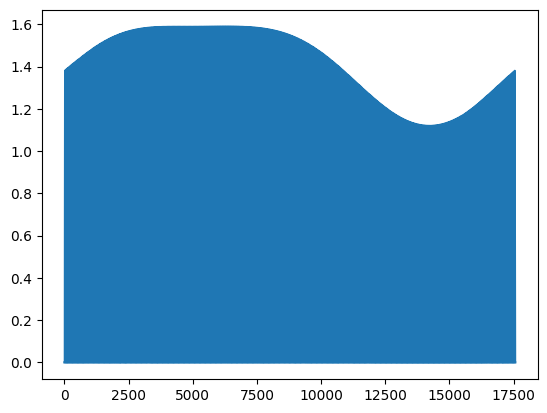

In [187]:
plt.plot(site_1_data['power_generation'])

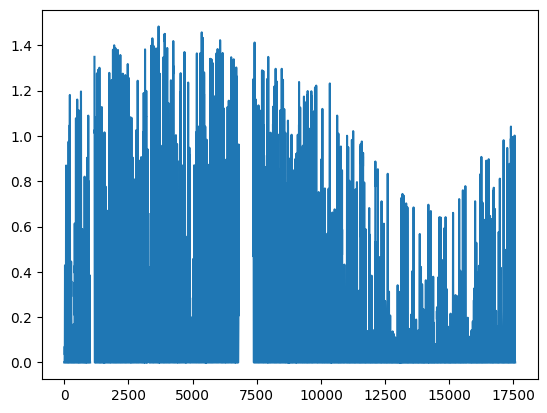

In [188]:
plt.plot(site_1_data['solar_gen_kwh'])

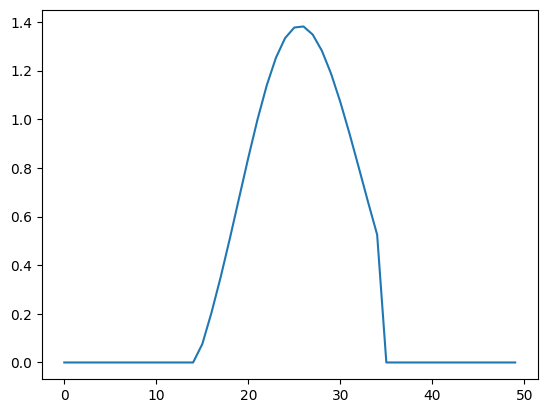

In [189]:
plt.plot(site_1_data['power_generation'][:50])

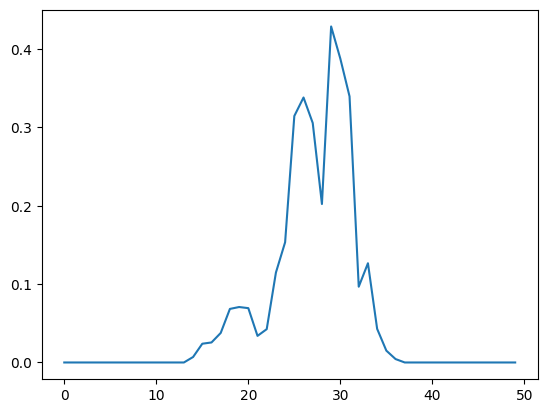

In [190]:
plt.plot(site_1_data['solar_gen_kwh'][:50])